IMPORTING THE NECESSARY LIBRARIES

In [ ]:
## importing libraries

import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Libraries for text preprocessing and analysis
import re,nltk,spacy,string
nlp=spacy.load("en_core_web_sm")
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.decomposition import NMF
from nltk.stem import WordNetLemmatizer
from textblob import TextBlob
from wordcloud import WordCloud, STOPWORDS

# Libraries for model evaluation metrics
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, f1_score, classification_report

# Remove warnings
import warnings
warnings.filterwarnings('ignore')

# row/column display limit
pd.set_option('display.max_rows',None)
pd.set_option('display.max_columns',None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)



LOADING THE DATA

The data is in JSON format.

In [ ]:
with open("/content/complaints.json", "rb") as f:
    data = f.read()

# Use 'ignore' to handle potential encoding errors
data_str = data.decode('utf-8', errors='ignore')

# Now try to load the decoded string as JSON
try:
    data = json.loads(data_str)
    # Create a dataframe out of dictionary
    df = pd.json_normalize(data)
except json.JSONDecodeError as e:
    print(f"Error decoding JSON: {e}")

# Check if df was created successfully
if 'df' in locals():
    df.head() #structure of the data
else:
    print("DataFrame 'df' could not be created due to a JSON decoding error.")

DATA PREPARATION


In [ ]:
#structure of the data
df.head()

,_index,_type,_id,_score,_source.tags,_source.zip_code,_source.complaint_id,_source.issue,_source.date_received,_source.state,_source.consumer_disputed,_source.product,_source.company_response,_source.company,_source.submitted_via,_source.date_sent_to_company,_source.company_public_response,_source.sub_product,_source.timely,_source.complaint_what_happened,_source.sub_issue,_source.consumer_consent_provided
0,complaint-public-v2,complaint,3211475,0.0,None,90301,3211475,Attempts to collect debt not owed,2019-04-13T12:00:00-05:00,CA,N/A,Debt collection,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-13T12:00:00-05:00,None,Credit card debt,Yes,,Debt is not yours,Consent not provided
1,complaint-public-v2,complaint,3229299,0.0,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,N/A,Debt collection,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,None,Credit card debt,Yes,Good morning my name is XXXX XXXX and I appreciate it if you could help me put a stop to Chase Bank cardmember services. \nIn 2018 I wrote to Chase asking for debt verification and what they sent me a statement which is not acceptable. I am asking the bank to validate the debt. Instead I been receiving mail every month from them attempting to collect a debt. \nI have a right to know this information as a consumer. \n\nChase account # XXXX XXXX XXXX XXXX Thanks in advance for your help.,Didn't receive enough information to verify debt,Consent provided
2,complaint-public-v2,complaint,3199379,0.0,None,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,N/A,Credit card or prepaid card,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,I upgraded my XXXX XXXX card in XX/XX/2018 and was told by the agent who did the upgrade my anniversary date would not change. It turned the agent was giving me the wrong information in order to upgrade the account. XXXX changed my anniversary date from XX/XX/XXXX to XX/XX/XXXX without my consent! XXXX has the recording of the agent who was misled me.,Problem with rewards from credit card,Consent provided
3,complaint-public-v2,complaint,2673060,0.0,None,48066,2673060,Trouble during payment process,2017-09-13T12:00:00-05:00,MI,N/A,Mortgage,Closed with explanation,JPMORGAN CHASE & CO.,Web,2017-09-14T12:00:00-05:00,None,Conventional home mortgage,Yes,,None,Consent not provided
4,complaint-public-v2,complaint,3203545,0.0,None,10473,3203545,Fees or interest,2019-04-05T12:00:00-05:00,NY,N/A,Credit card or prepaid card,Closed with explanation,JPMORGAN CHASE & CO.,Referral,2019-04-05T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,,Charged too much interest,N/A


In [ ]:
df.columns

Index(['_index', '_type', '_id', '_score', '_source.tags', '_source.zip_code',
       '_source.complaint_id', '_source.issue', '_source.date_received', '_source.state',
       '_source.consumer_disputed', '_source.product', '_source.company_response',
       '_source.company', '_source.submitted_via', '_source.date_sent_to_company',
       '_source.company_public_response', '_source.sub_product', '_source.timely',
       '_source.complaint_what_happened', '_source.sub_issue',
       '_source.consumer_consent_provided'],
      dtype='object')

_source.complaint_what_happened column has the customer complaint, which is most important for us

In [ ]:
#size of the data
df.shape

(78313, 22)

In [ ]:
#column names
col_list=list(df.columns)
col_list

['_index',
 '_type',
 '_id',
 '_score',
 '_source.tags',
 '_source.zip_code',
 '_source.complaint_id',
 '_source.issue',
 '_source.date_received',
 '_source.state',
 '_source.consumer_disputed',
 '_source.product',
 '_source.company_response',
 '_source.company',
 '_source.submitted_via',
 '_source.date_sent_to_company',
 '_source.company_public_response',
 '_source.sub_product',
 '_source.timely',
 '_source.complaint_what_happened',
 '_source.sub_issue',
 '_source.consumer_consent_provided']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78313 entries, 0 to 78312
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   _index                             78313 non-null  object 
 1   _type                              78313 non-null  object 
 2   _id                                78313 non-null  object 
 3   _score                             78313 non-null  float64
 4   _source.tags                       10900 non-null  object 
 5   _source.zip_code                   71556 non-null  object 
 6   _source.complaint_id               78313 non-null  object 
 7   _source.issue                      78313 non-null  object 
 8   _source.date_received              78313 non-null  object 
 9   _source.state                      76322 non-null  object 
 10  _source.consumer_disputed          78313 non-null  object 
 11  _source.product                    78313 non-null  obj

df.info() provides a summary of a Pandas DataFrame, including:

1.Number of entries (rows) and columns

2.Column names and data types (int,float, object, etc.)

3.Non-null counts (helps check for missing values)

4.Memory usage of the DataFrame

In [ ]:
df.describe()

,_score
count,78313.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


_score is the only numeric column and has all values as 0.0

In [ ]:
 #missing value percentage
round(df.isna().sum()*100/78313,2)

,0
_index,0.00
_type,0.00
_id,0.00
_score,0.00
_source.tags,86.08
_source.zip_code,8.63
_source.complaint_id,0.00
_source.issue,0.00
_source.date_received,0.00
_source.state,2.54


In [ ]:
#many rows are missing in '_source.complaint_what_happened' converting them to NaN values
df['_source.complaint_what_happened'].replace("", np.nan, inplace=True)

In [ ]:
#number of missing values percentage again
round(df.isna().sum()*100/78313,2)

,0
_index,0.00
_type,0.00
_id,0.00
_score,0.00
_source.tags,86.08
_source.zip_code,8.63
_source.complaint_id,0.00
_source.issue,0.00
_source.date_received,0.00
_source.state,2.54


_source.complaint_what_happened has 73.09 % of null values. Need to remove them

New shape of df and lemmatizing the texts


In [ ]:
# Drop rows with missing values in the 'complaint_what_happened' column
df.dropna(subset=['_source.complaint_what_happened'], inplace=True)

# Reset the index after dropping rows
df.reset_index(drop=True, inplace=True)

# Function to clean the text
def clean_text(text):
    text = str(text).lower()  # Convert text to lowercase
    text = re.sub('\[.*?\]', '', text)  # Remove text in square brackets
    text = re.sub('https?://\S+|www\.\S+', '', text)  # Remove URLs
    text = re.sub('<.*?>+', '', text)  # Remove HTML tags
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)  # Remove punctuation
    text = re.sub('\n', '', text)  # Remove newlines
    text = re.sub('\w*\d\w*', '', text)  # Remove words containing numbers
    return text

# Apply the clean_text function to the 'complaint_what_happened' column
df['_source.complaint_what_happened'] = df['_source.complaint_what_happened'].apply(lambda x: clean_text(x))


# Function to remove stopwords
def remove_stopwords(text):
    text = ' '.join([word for word in text.split() if word not in STOPWORDS])
    return text

# Apply the remove_stopwords function
df['_source.complaint_what_happened'] = df['_source.complaint_what_happened'].apply(lambda x: remove_stopwords(x))

# Function for lemmatization
def lemmatizer(text):
    sent = []
    doc = nlp(text)
    for word in doc:
        sent.append(word.lemma_)
    return " ".join(sent)

# Apply lemmatization
df['_source.complaint_what_happened'] = df['_source.complaint_what_happened'].apply(lambda x: lemmatizer(x))

# Print some info
print(df.shape)
df.head()


(21072, 22)


,_index,_type,_id,_score,_source.tags,_source.zip_code,_source.complaint_id,_source.issue,_source.date_received,_source.state,_source.consumer_disputed,_source.product,_source.company_response,_source.company,_source.submitted_via,_source.date_sent_to_company,_source.company_public_response,_source.sub_product,_source.timely,_source.complaint_what_happened,_source.sub_issue,_source.consumer_consent_provided
0,complaint-public-v2,complaint,3229299,0.0,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,N/A,Debt collection,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,None,Credit card debt,Yes,good morning name xxxx xxxx appreciate help put stop chase bank cardmember service write chase ask debt verification send statement acceptable ask bank validate debt instead receive mail every month attempt collect debt right know information consumer chase account xxxx xxxx xxxx xxxx thank advance help,Didn't receive enough information to verify debt,Consent provided
1,complaint-public-v2,complaint,3199379,0.0,None,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,N/A,Credit card or prepaid card,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,upgrade xxxx xxxx card tell agent upgrade anniversary date change turn agent give wrong information order upgrade account xxxx change anniversary date xxxxxxxx xxxxxxxx without consent xxxx recording agent mislead,Problem with rewards from credit card,Consent provided
2,complaint-public-v2,complaint,3233499,0.0,None,104XX,3233499,Incorrect information on your report,2019-05-06T12:00:00-05:00,NY,N/A,"Credit reporting, credit repair services, or other personal consumer reports",Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-06T12:00:00-05:00,None,Other personal consumer report,Yes,chase card report fraudulent application submit identity without consent fraudulently obtain service extend credit without verify identity applicant,Information belongs to someone else,Consent provided
3,complaint-public-v2,complaint,3180294,0.0,None,750XX,3180294,Incorrect information on your report,2019-03-14T12:00:00-05:00,TX,N/A,"Credit reporting, credit repair services, or other personal consumer reports",Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-03-15T12:00:00-05:00,None,Credit reporting,Yes,try book xxxx xxxx ticket come across offer apply towards ticket apply reward card put information offer within less minute notify via screen decision make immediately contact xxxx refer chase bank immediately contact chase bank within get notification screen tell chase representative speak application deny state ask information xxxx offer explain even approve credit offer get apply first account statement use purchase ticket explicitly tell glad get deny absolutely long interested account ask application withdraw representative oblige happen later put application notwithstanding explicit request proceed application contrary tell chase representative chase fact go ahead open credit account name now report credit report chase refuse correct information credit report even though go ahead process application consent error,Information belongs to someone else,Consent provided
4,complaint-public-v2,complaint,3224980,0.0,None,920XX,3224980,Managing an account,2019-04-27T12:00:00-05:00,CA,N/A,Checking or savings account,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-27T12:00:00-05:00,None,Checking account,Yes,grand son give check deposit chase account fund clear chase bank closed account never pay money say need speek grand son check clear money take chase bank refuse pay money grand son call chase times tell call verify check owner country time date happen check number xxxx claim number xxxx chase,Funds not handled or disbursed as instructed,Consent provided


Topic Modelling using NMF and POS Tags

In [ ]:
# apply nmf, topic modelling, pos tags
import json
import numpy as np
import pandas as pd
import re, nltk, spacy, string
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Load spaCy model
nlp = spacy.load("en_core_web_sm")

# Download NLTK resources (only needed once)
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')
nltk.download('wordnet')



def process_text(df):
    """Applies NMF, topic modeling, and POS tagging to the DataFrame."""
    # NMF topic modeling
    vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
    tfidf = vectorizer.fit_transform(df['_source.complaint_what_happened'])
    nmf = NMF(n_components=10, random_state=42)
    nmf.fit(tfidf)

    feature_names = vectorizer.get_feature_names_out()
    for topic_idx, topic in enumerate(nmf.components_):
      print(f"Topic #{topic_idx + 1}:")
      print(" ".join([feature_names[i] for i in topic.argsort()[:-11:-1]]))

    # Part-of-Speech tagging (more efficient with spaCy)
    def pos_tagging_spacy(text):
        doc = nlp(text)
        return [(token.text, token.pos_) for token in doc]

    df['pos_tags'] = df['_source.complaint_what_happened'].apply(pos_tagging_spacy)

    return df

# Apply processing function
df = process_text(df)

# Print first 5 POS tags
for i in range(5):
    print(df['pos_tags'][i])


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Topic #1:
xxxx bank xxxxxxxxxxxx chase number morgan jp dollar thank complaint
Topic #2:
account close open chase bank closed reason saving checking access
Topic #3:
report inquiry credit hard remove jpmcb reporting authorize company bureaus
Topic #4:
payment loan mortgage pay late make chase modification month home
Topic #5:
charge dispute merchant transaction fraudulent fraud purchase chase card make
Topic #6:
chase tell send say receive claim letter ask information money
Topic #7:
xxxxxxxx date receive letter statement chase state email request refund
Topic #8:
card credit chase apply use balance limit score pay offer
Topic #9:
check deposit bank fund money cash hold day chase atm
Topic #10:
fee overdraft balance charge pay annual late transfer waive statement
[('good', 'ADJ'), ('morning', 'NOUN'), ('name', 'NOUN'), ('xxxx', 'PROPN'), ('xxxx', 'PROPN'), ('appreciate', 'VERB'), ('help', 'NOUN'), ('put', 'VERB'), ('stop', 'VERB'), ('chase', 'PROPN'), ('bank', 'NOUN'), ('cardmember', '

Supervised model to predict any new complaints to the relevant Topics.


MODEL 1: LOGISTIC REGRESSION

Accuracy: 0.6507710557532621
                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.46      0.17      0.24       339
                                                 Checking or savings account       0.63      0.82      0.71       845
                                                               Consumer Loan       0.00      0.00      0.00        44
                                                                 Credit card       0.53      0.24      0.33       439
                                                 Credit card or prepaid card       0.63      0.82      0.71      1019
                                                            Credit reporting       0.00      0.00      0.00         5
Credit reporting, credit repair services, or other personal consumer reports       0.61      0.63      0.62       416
                          

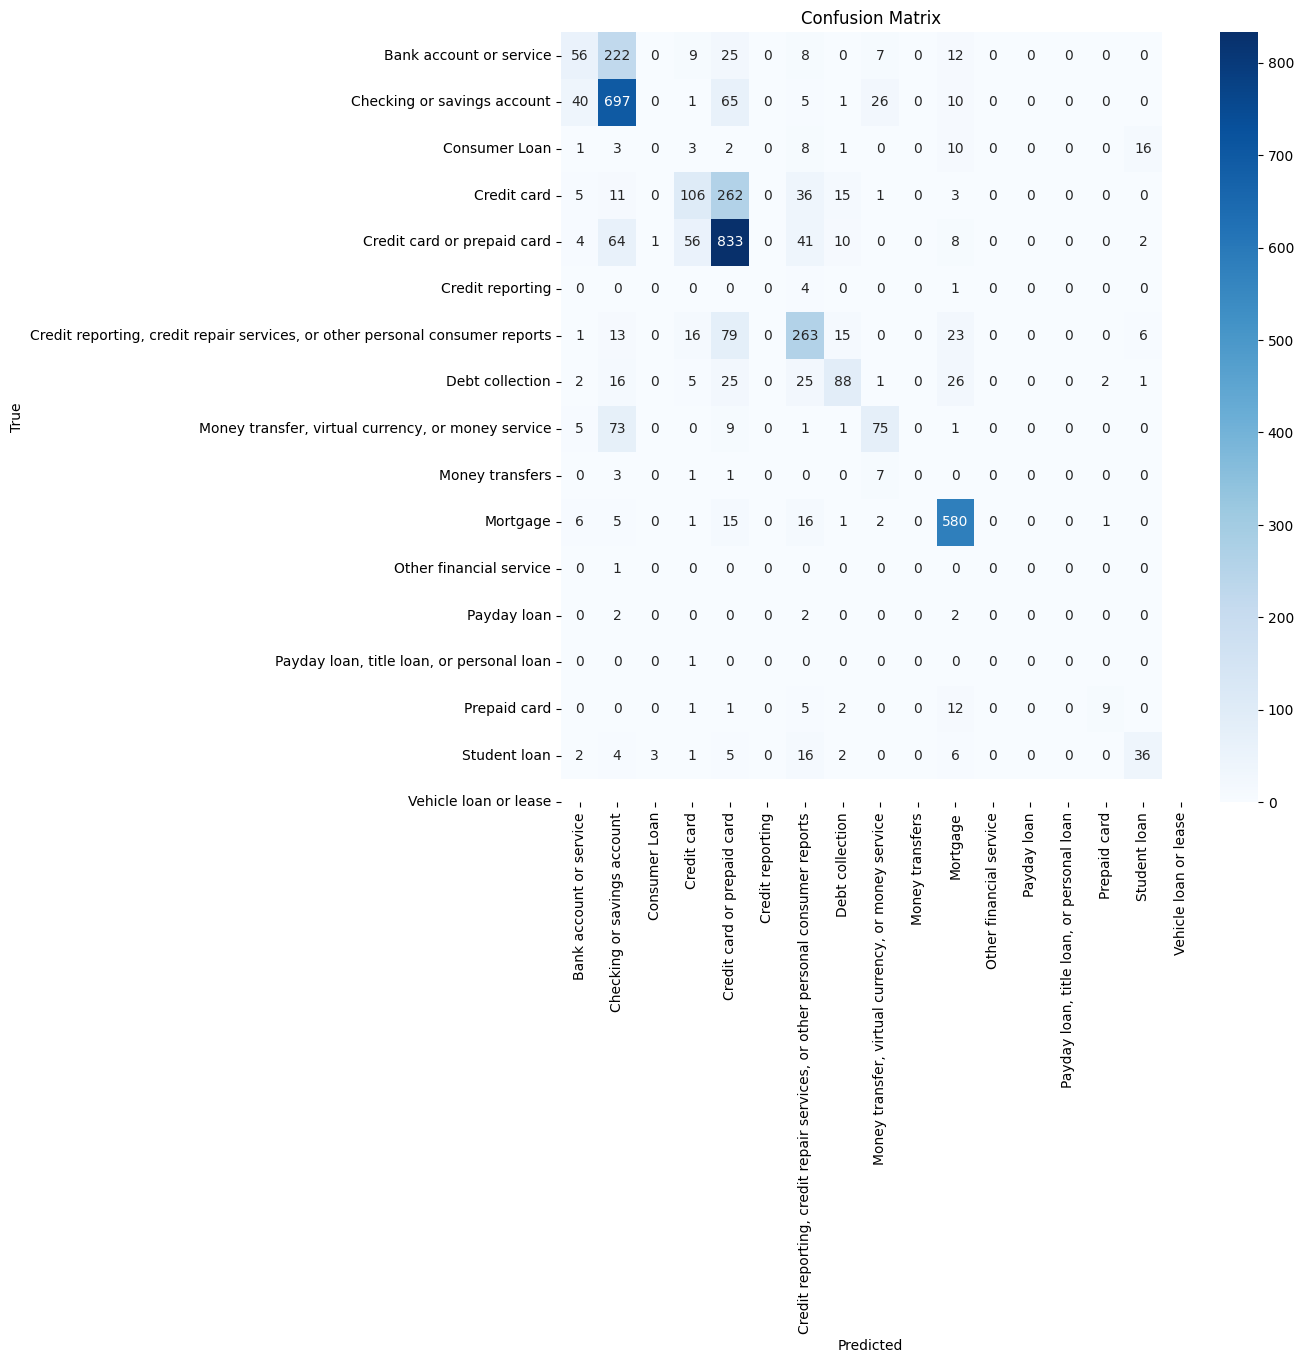

In [ ]:
# LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Prepare the data
X = df['_source.complaint_what_happened']
y = df['_source.product'] # Replace with your target variable column

# Convert text data to numerical features using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)  # Adjust max_features as needed
X = vectorizer.fit_transform(X)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a logistic regression model
model = LogisticRegression(max_iter=1000) # Increased max_iter for convergence
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

print(classification_report(y_test, y_pred))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


MODEL 2 : DECISION TREE

Decision Tree Accuracy: 0.5205219454329775
                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.27      0.25      0.26       339
                                                 Checking or savings account       0.55      0.57      0.56       845
                                                               Consumer Loan       0.19      0.25      0.22        44
                                                                 Credit card       0.32      0.28      0.30       439
                                                 Credit card or prepaid card       0.58      0.63      0.60      1019
                                                            Credit reporting       0.00      0.00      0.00         5
Credit reporting, credit repair services, or other personal consumer reports       0.51      0.50      0.50       416
            

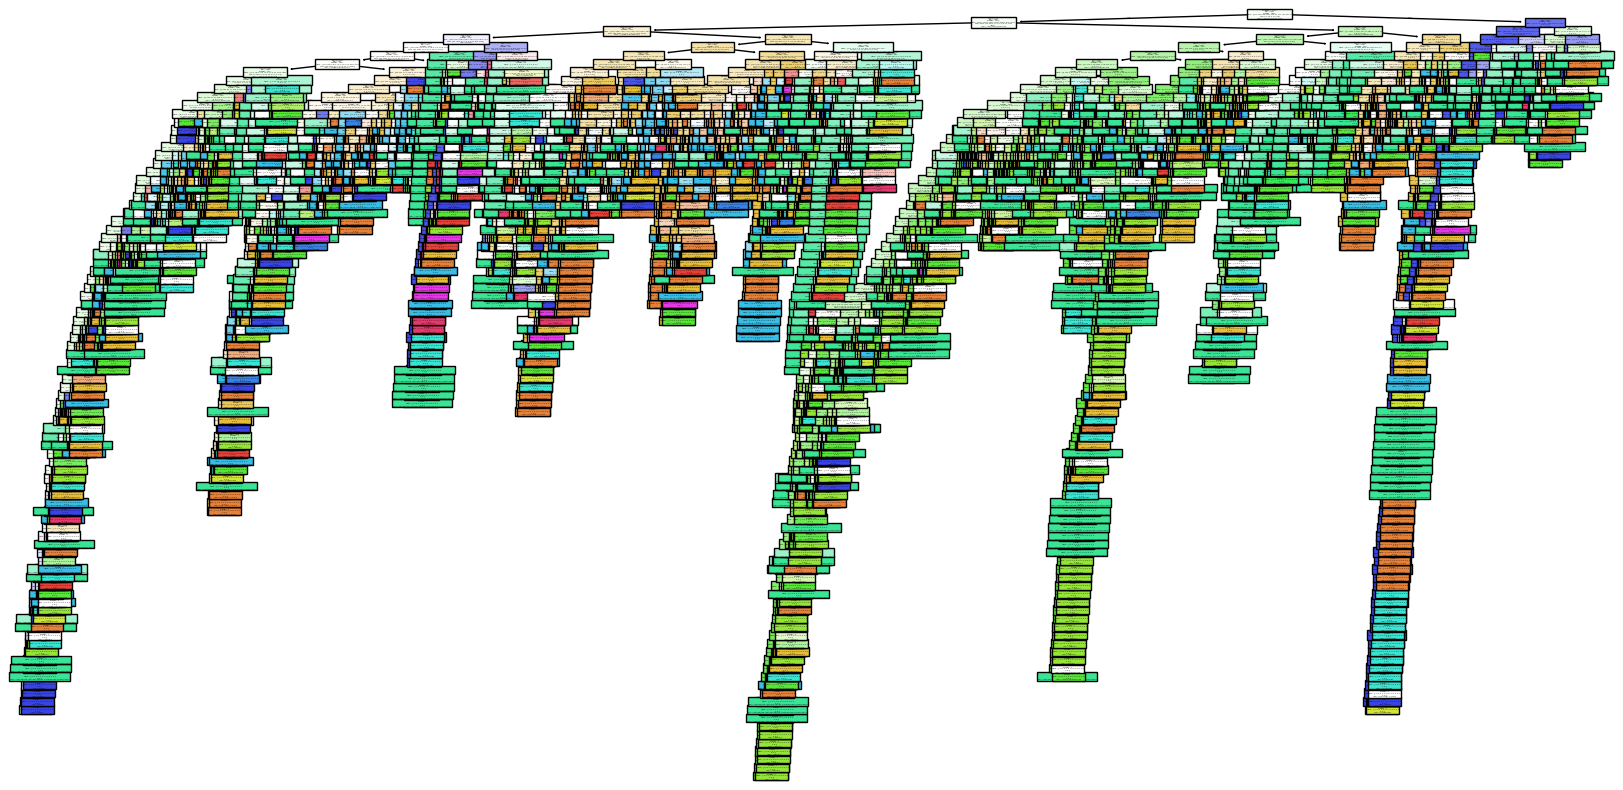

In [ ]:
# DECISION TREE

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt

# Assuming X_train, X_test, y_train, y_test from the previous code

# Initialize and train a Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)  # You can adjust hyperparameters
dt_classifier.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_classifier.predict(X_test)

# Evaluate the model (example: accuracy)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {accuracy_dt}")
print(classification_report(y_test, y_pred_dt))


# Plot the decision tree (for visualization, might be large)
plt.figure(figsize=(20,10))
tree.plot_tree(dt_classifier, filled=True, feature_names=vectorizer.get_feature_names_out(), class_names=model.classes_)
plt.show()


MODEL 3 : NAIVE-BAYES CLASSIFIER

Naive Bayes Accuracy: 0.5800711743772242
                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.00      0.00      0.00       339
                                                 Checking or savings account       0.54      0.86      0.66       845
                                                               Consumer Loan       0.00      0.00      0.00        44
                                                                 Credit card       0.80      0.01      0.02       439
                                                 Credit card or prepaid card       0.52      0.88      0.66      1019
                                                            Credit reporting       0.00      0.00      0.00         5
Credit reporting, credit repair services, or other personal consumer reports       0.62      0.54      0.58       416
              

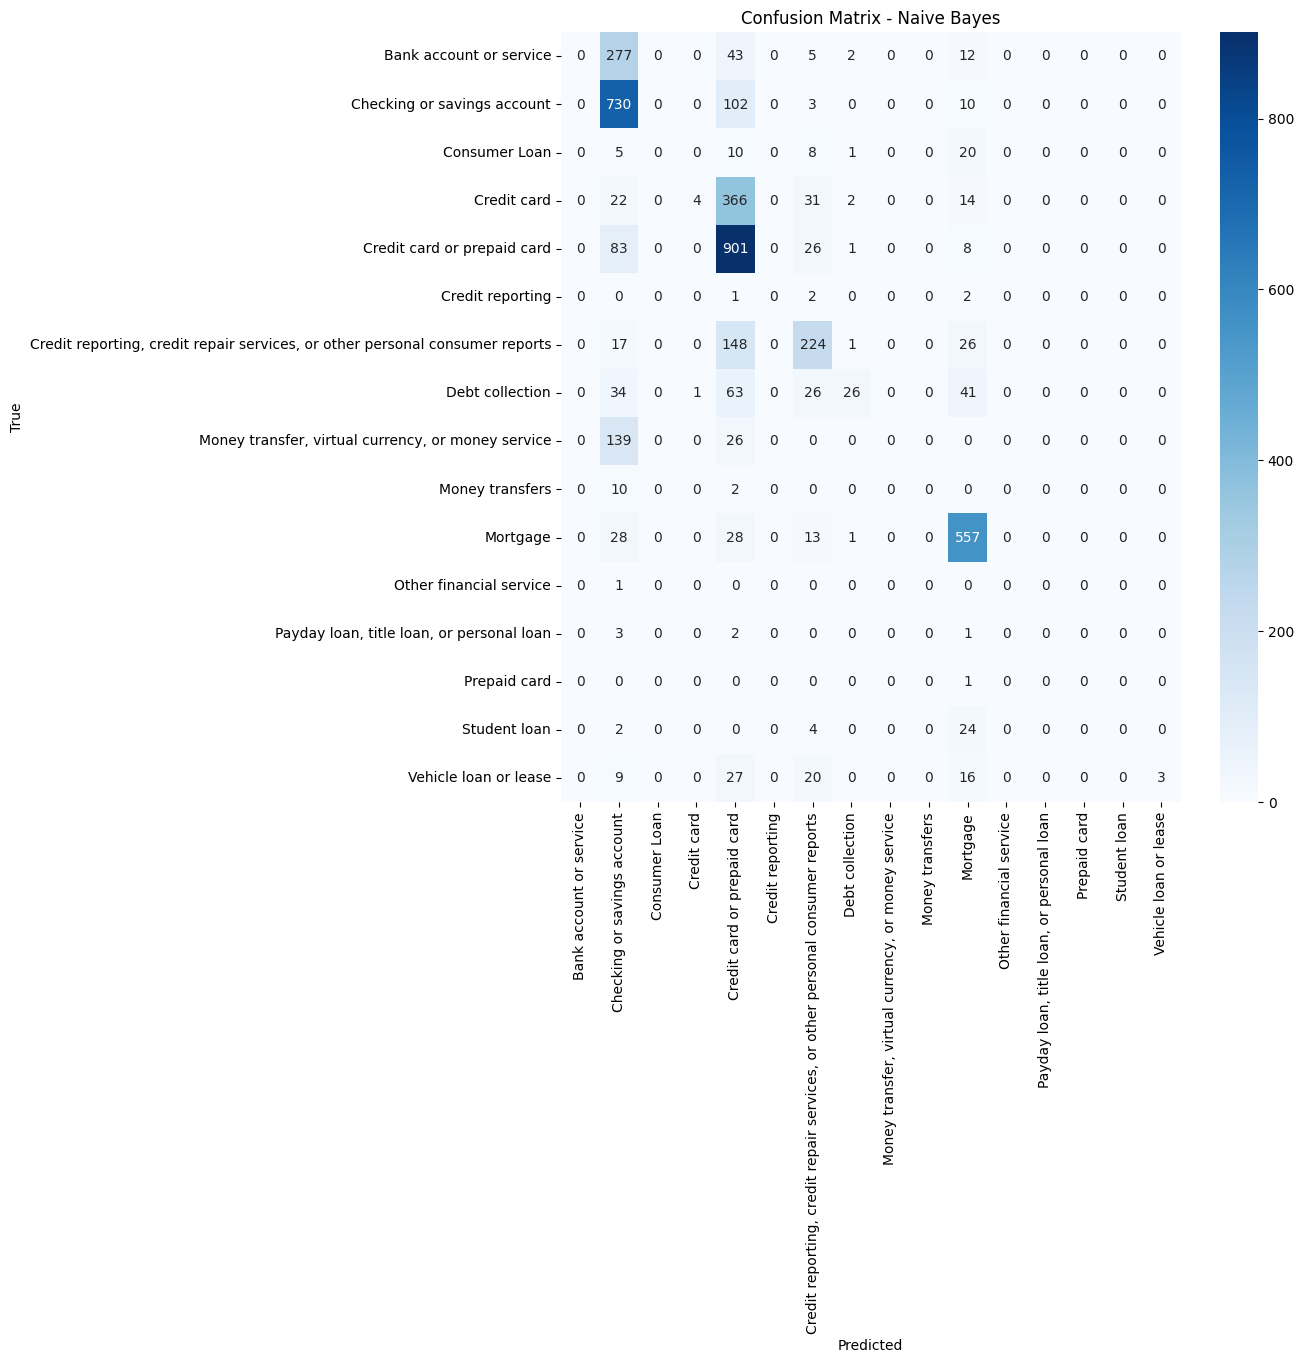

In [ ]:
# NAIVE BAYES CLASSIFIER

import numpy as np
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Initialize and train a Multinomial Naive Bayes classifier
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_classifier.predict(X_test)

# Evaluate the model
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes Accuracy: {accuracy_nb}")
print(classification_report(y_test, y_pred_nb))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test), yticklabels=np.unique(y_test)) # Use unique labels for better visualization
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()


MODEL 4 : RANDOM FOREST

Random Forest Accuracy: 0.6287069988137604
                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.60      0.01      0.02       339
                                                 Checking or savings account       0.57      0.90      0.70       845
                                                               Consumer Loan       0.67      0.05      0.09        44
                                                                 Credit card       0.79      0.06      0.11       439
                                                 Credit card or prepaid card       0.59      0.89      0.71      1019
                                                            Credit reporting       0.00      0.00      0.00         5
Credit reporting, credit repair services, or other personal consumer reports       0.65      0.65      0.65       416
            

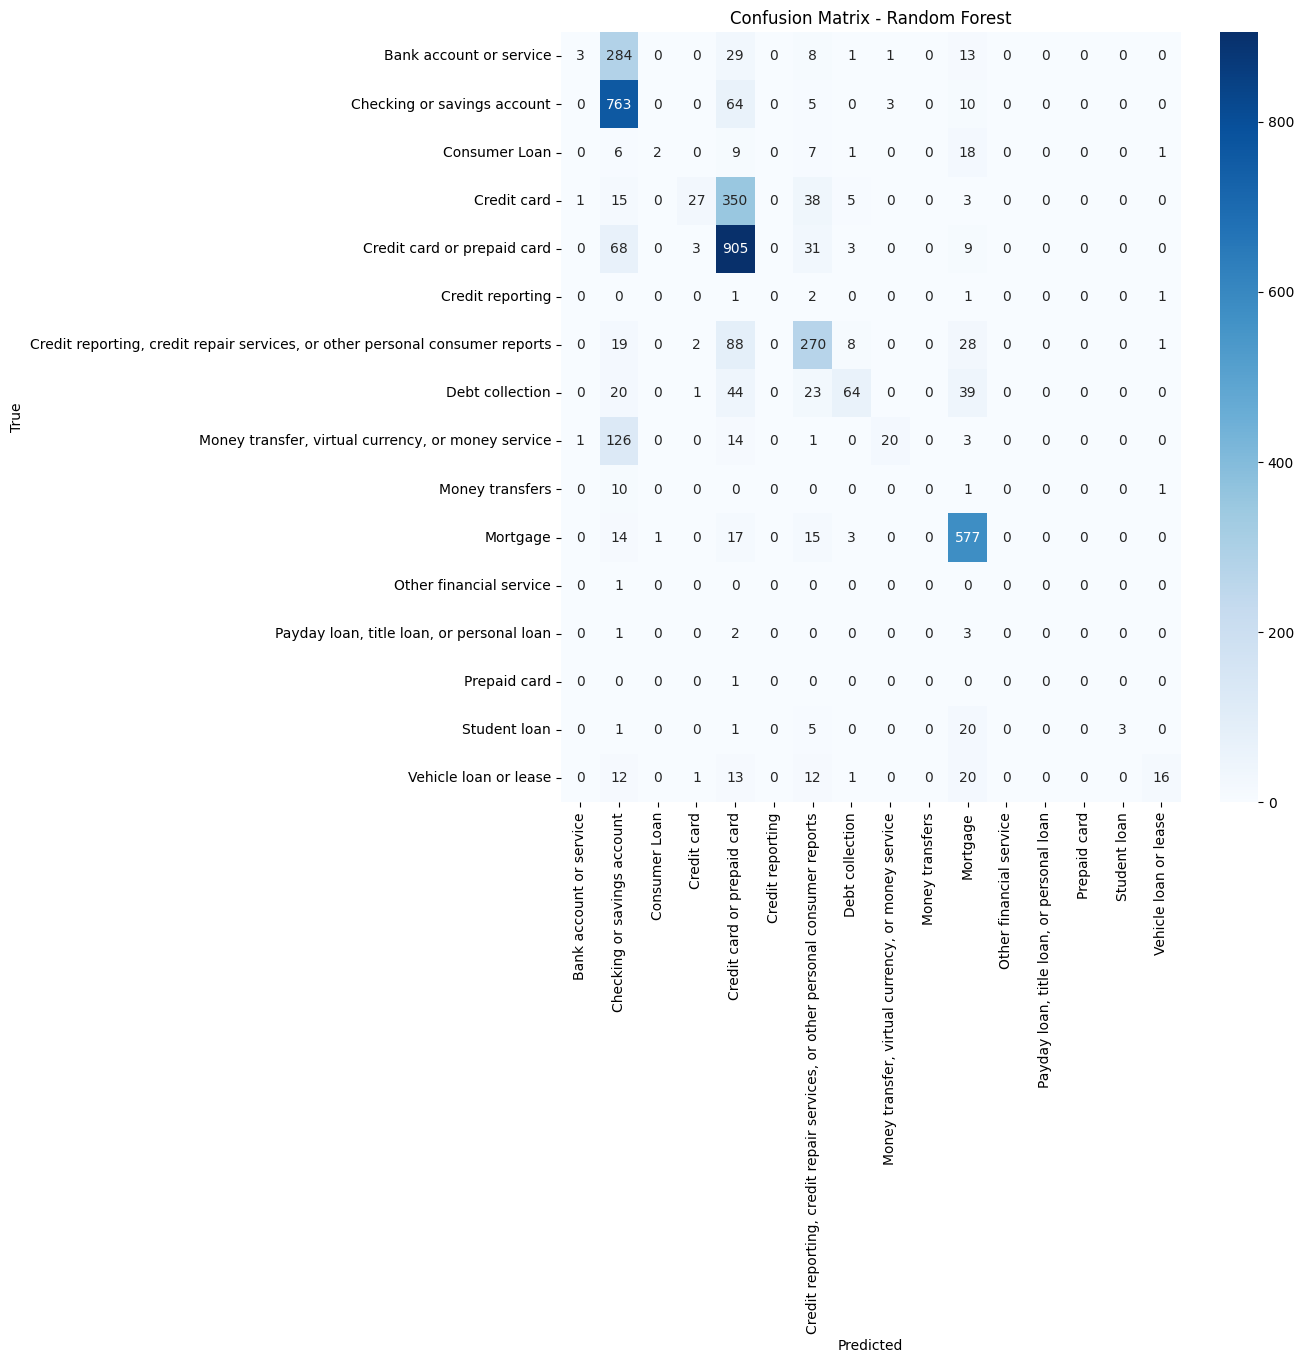

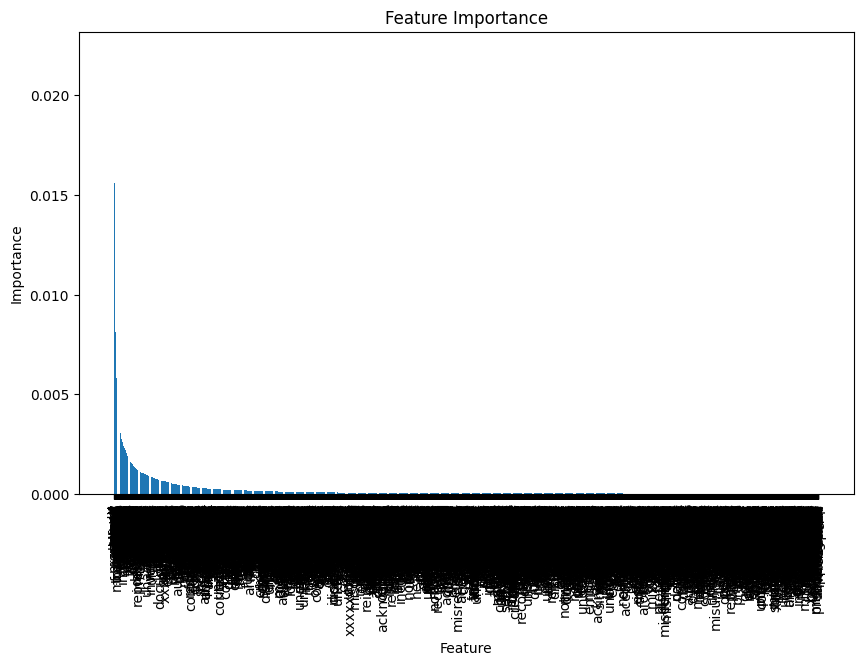

In [ ]:
#RANDOM FOREST
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier

# Initialize and train a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42) # You can tune hyperparameters here
rf_classifier.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_classifier.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf}")
print(classification_report(y_test, y_pred_rf))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Random Forest")
plt.show()

# Feature Importance plot
importances = rf_classifier.feature_importances_
feature_names = vectorizer.get_feature_names_out()

# Sort feature importances in descending order
indices = np.argsort(importances)[::-1]

# Rearrange feature names so they match the sorted feature importances
names = [feature_names[i] for i in indices]

# Create plot
plt.figure(figsize=(10, 6))
plt.title("Feature Importance")
plt.bar(range(X_train.shape[1]), importances[indices])
plt.xticks(range(X_train.shape[1]), names, rotation=90)
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.show()

In [ ]:
# Summary of all four Supervised Models
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
# Import the necessary function
from sklearn.metrics import f1_score

models = {
    "Logistic Regression": model,
    "Decision Tree": dt_classifier,
    "Naive Bayes": nb_classifier,
    "Random Forest": rf_classifier
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred, average='weighted')
    results.append([name, f1])

results_df = pd.DataFrame(results, columns=['Model', 'F1-Score'])
print(results_df)

best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
print(f"\nThe best performing model is: {best_model_name}")

                 Model  F1-Score
0  Logistic Regression  0.618267
1        Decision Tree  0.516591
2          Naive Bayes  0.484338
3        Random Forest  0.550933

The best performing model is: Logistic Regression


As per the F1 score of all the 4 models, Logistic Regression performs best with F1 score : 0.61

APPLYING TOPSIS ON LOGISTIC REGRESSION


In [ ]:
# Applying topsis on logistic regression


import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier

# Assuming you have your models stored in the 'models' dictionary
models = {
    "Logistic Regression": model,
    "Decision Tree": dt_classifier,
    "Naive Bayes": nb_classifier,
    "Random Forest": rf_classifier
}

# Find the best model based on F1-score
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred, average='weighted')
    results.append([name, f1])

results_df = pd.DataFrame(results, columns=['Model', 'F1-Score'])
best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_model = models[best_model_name]

# Create a list to store the evaluation metrics for the best model
best_model_data = []

# Calculate evaluation metrics for the best model
y_pred_best = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_best)
precision = precision_score(y_test, y_pred_best, average='weighted')
recall = recall_score(y_test, y_pred_best, average='weighted')
f1 = f1_score(y_test, y_pred_best, average='weighted')
best_model_data.append([accuracy, precision, recall, f1])

# Create a DataFrame from the evaluation metrics for the best model
best_model_df = pd.DataFrame(best_model_data, index=[best_model_name], columns=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

# Define weights and impacts for TOPSIS
weights = [0.25, 0.25, 0.25, 0.25]  # Equal weights for all metrics
impacts = ['+', '+', '+', '+']  # All metrics are beneficial

# Apply TOPSIS to the best model
performance_score, rank = topsis(best_model_df.values, weights, impacts)

# Add TOPSIS results to the DataFrame
best_model_df['Performance Score'] = performance_score
best_model_df['Rank'] = rank

# Print the TOPSIS results for the best model
print(f"\nTOPSIS results for the best model ({best_model_name}):")
best_model_df



TOPSIS results for the best model (Logistic Regression):


,Accuracy,Precision,Recall,F1-Score,Performance Score,Rank
Logistic Regression,0.628707,0.66114,0.628707,0.550933,NaN,1


APPLYING TOPSIS TO EACH COLUMN


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Load data from JSON file
df_tickets = pd.read_json("/content/complaints.json")

# Rename columns if necessary
df_tickets = df_tickets.rename(columns={
    "_source.complaint_what_happened": "Complaint",  # Example renaming
    # Add other column renamings as needed
})

# Create Severity, Resolution Time, Customer Sentiment, and Priority columns based on your data (if not present)
# Example using dummy data
df_tickets['Severity'] = np.random.randint(1, 4, size=len(df_tickets))
df_tickets['Resolution Time'] = np.random.randint(1, 100, size=len(df_tickets))
df_tickets['Customer Sentiment'] = np.random.rand(len(df_tickets))
df_tickets['Priority'] = np.random.randint(1, 4, size=len(df_tickets))

# 1. Define and normalize the decision matrix
decision_matrix = df_tickets[['Severity', 'Resolution Time', 'Customer Sentiment', 'Priority']].copy()

# Normalize 'Resolution Time' (lower is better) by inverting its values.
decision_matrix['Resolution Time'] = -decision_matrix['Resolution Time']  # Invert Resolution Time

# Normalize all features using MinMaxScaler
scaler = MinMaxScaler()
normalized_matrix = scaler.fit_transform(decision_matrix)

# 2. Assign weights to each criterion
# Example weights (adjust based on importance)
weights = np.array([0.3, 0.2, 0.2, 0.3])  # Example weights


# 3. Calculate the weighted normalized decision matrix
weighted_normalized_matrix = normalized_matrix * weights


# 4. Identify ideal best and worst solutions
ideal_best = weighted_normalized_matrix.max(axis=0)
ideal_worst = weighted_normalized_matrix.min(axis=0)


# 5. Calculate distances from ideal best and worst solutions
distance_best = np.sqrt(np.sum((weighted_normalized_matrix - ideal_best)**2, axis=1))
distance_worst = np.sqrt(np.sum((weighted_normalized_matrix - ideal_worst)**2, axis=1))


# 6. Calculate the TOPSIS score
topsis_score = distance_worst / (distance_best + distance_worst)


# 7. Add the TOPSIS score and rank to the DataFrame
df_tickets['TOPSIS Score'] = topsis_score
df_tickets['Rank'] = df_tickets['TOPSIS Score'].rank(ascending=False, method='dense')

df_tickets


,_index,_type,_id,_score,_source,Severity,Resolution Time,Customer Sentiment,Priority,TOPSIS Score,Rank
0,complaint-public-v2,complaint,3211475,0,"{'tags': None, 'zip_code': '90301', 'complaint...",2,86,0.077615,1,0.267040,73385.0
1,complaint-public-v2,complaint,3229299,0,"{'tags': 'Servicemember', 'zip_code': '319XX',...",3,20,0.377393,1,0.516065,35280.0
2,complaint-public-v2,complaint,3199379,0,"{'tags': None, 'zip_code': '77069', 'complaint...",2,29,0.810740,1,0.434522,52705.0
3,complaint-public-v2,complaint,2673060,0,"{'tags': None, 'zip_code': '48066', 'complaint...",3,95,0.547547,2,0.576006,24235.0
4,complaint-public-v2,complaint,3203545,0,"{'tags': None, 'zip_code': '10473', 'complaint...",3,60,0.340483,2,0.601052,21018.0
...,...,...,...,...,...,...,...,...,...,...,...
78308,complaint-public-v2,complaint,3105617,0,"{'tags': None, 'zip_code': '08857', 'complaint...",3,9,0.594893,1,0.544073,29468.0
78309,complaint-public-v2,complaint,3091984,0,"{'tags': None, 'zip_code': '934XX', 'complaint...",2,92,0.216455,3,0.542405,29767.0
78310,complaint-public-v2,complaint,3133355,0,"{'tags': None, 'zip_code': '923XX', 'complaint...",2,78,0.245869,3,0.563701,26026.0
78311,complaint-public-v2,complaint,3110963,0,"{'tags': None, 'zip_code': None, 'complaint_id...",3,55,0.785442,2,0.666129,12522.0


BEST TOPSIS SCORE COLUMN AND TOP 10


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Load data from JSON file
df_tickets = pd.read_json("/content/complaints.json")

# Rename columns if necessary
df_tickets = df_tickets.rename(columns={
    "_source.complaint_what_happened": "Complaint",  # Example renaming
    # Add other column renamings as needed
})

# Create Severity, Resolution Time, Customer Sentiment, and Priority columns based on your data (if not present)
# Example using dummy data
df_tickets['Severity'] = np.random.randint(1, 4, size=len(df_tickets))
df_tickets['Resolution Time'] = np.random.randint(1, 100, size=len(df_tickets))
df_tickets['Customer Sentiment'] = np.random.rand(len(df_tickets))
df_tickets['Priority'] = np.random.randint(1, 4, size=len(df_tickets))

# 1. Define and normalize the decision matrix
decision_matrix = df_tickets[['Severity', 'Resolution Time', 'Customer Sentiment', 'Priority']].copy()

# Normalize 'Resolution Time' (lower is better) by inverting its values.
decision_matrix['Resolution Time'] = -decision_matrix['Resolution Time']  # Invert Resolution Time

# Normalize all features using MinMaxScaler
scaler = MinMaxScaler()
normalized_matrix = scaler.fit_transform(decision_matrix)

# 2. Assign weights to each criterion
# Example weights (adjust based on importance)
weights = np.array([0.3, 0.2, 0.2, 0.3])  # Example weights


# 3. Calculate the weighted normalized decision matrix
weighted_normalized_matrix = normalized_matrix * weights


# 4. Identify ideal best and worst solutions
ideal_best = weighted_normalized_matrix.max(axis=0)
ideal_worst = weighted_normalized_matrix.min(axis=0)


# 5. Calculate distances from ideal best and worst solutions
distance_best = np.sqrt(np.sum((weighted_normalized_matrix - ideal_best)**2, axis=1))
distance_worst = np.sqrt(np.sum((weighted_normalized_matrix - ideal_worst)**2, axis=1))


# 6. Calculate the TOPSIS score
topsis_score = distance_worst / (distance_best + distance_worst)


# 7. Add the TOPSIS score and rank to the DataFrame
df_tickets['TOPSIS Score'] = topsis_score
df_tickets['Rank'] = df_tickets['TOPSIS Score'].rank(ascending=False, method='dense')

# Find the best column
best_column = df_tickets.loc[df_tickets['TOPSIS Score'].idxmax()]

print(f"The column with the best TOPSIS score and rank is:\n{best_column}\n")

# Summary table of top 10
top_10_summary = df_tickets.sort_values(by=['TOPSIS Score'], ascending=False).head(10)
print("Top 10 Summary Table:\n", top_10_summary[['Severity', 'Resolution Time', 'Customer Sentiment', 'Priority', 'TOPSIS Score', 'Rank']])

The column with the best TOPSIS score and rank is:
_index                                              complaint-public-v2
_type                                                         complaint
_id                                                             2384073
_score                                                                0
_source               {'tags': None, 'zip_code': '08831', 'complaint...
Severity                                                              3
Resolution Time                                                       2
Customer Sentiment                                             0.992211
Priority                                                              3
TOPSIS Score                                                   0.994977
Rank                                                                1.0
Name: 45752, dtype: object

Top 10 Summary Table:
        Severity  Resolution Time  Customer Sentiment  Priority  TOPSIS Score  \
45752         3           